# 5.3 Learning-based segmentation. SAM

**Learning-based segmentation** techniques use deep neural networks that learn both the feature representation and the decision rule from data. They follow the typical pipeline of this Artificial Intelligence branch:
- A huge dataset with segmented regions is collected.
- A model architecture is designed.
- The model is trained with the dataset until its performance is over the application requirements.
- It is released/deployed.

Depending on the task, these models perform **semantic segmentation** (a class label per pixel), **instance segmentation** (class + instance ID for countable objects), **panoptic segmentation** (both combined) or **promptable / class-agnostic segmentation**. In this notebook we will explore the Segment Anything Model (SAM), a promptable segmentation model.

## Problem context - Region segmentation to calculate vegetation indices

In our country, climate change is causing serious problems for green areas, as periods of drought are becoming more frequent due to a lack of rain. This situation compromises the irrigation of gardens and crops, often leading to water supply cuts or the use of reclaimed water, which is not always ideal for plants.

Precision agriculture offers a way to mitigate this issue through the monitoring of green areas and the extraction of indices that can help estimate the plants' condition. These indices can measure factors like water stress (lack of water), the presence of disease, vegetative vigor, etc. With this information, we can provide tailored treatment to plants based on their specific needs, optimizing water usage and reducing waste.

<center>
    <img src="https://raw.githubusercontent.com/jotaraul/cv_hub/refs/heads/main/segmentation/images_crops/expected_segmentation_and_ndvi_result_2.PNG" width="600">
    <figcaption>Fig. 1. Trees of a crop field segmented with SAM; the color of each circle shows the health of the tree according to its mean <a href="https://en.wikipedia.org/wiki/Normalized_difference_vegetation_index">Normalized Difference Vegetation Index (NDVI)</a>.</figcaption>
</center>

Computer vision to the rescue! In this practical exercise, our task is to segment trees visible in an image of a crop field captured by a drone. By doing so, we can extract personalized data for each tree, allowing us to provide the exact amount of water each one needs. This exercise introduces an essential application of computer vision in environmental sustainability and precision farming.




## Preparing our setup

To work with SAM you need to request GPU power from Google Colab (for example, a T4 GPU).

Let's start by installing the required python packages to work with SAM:

In [1]:
!pip3 install segment_anything
!wget -nc https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth # Download model weights (only if not downloaded yet)
import os
sam_checkpoint = os.path.abspath("sam_vit_h_4b8939.pth") # Full path, since the next code cell may change the working directory
# Model checkpoints
# vit_h, https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth
# vit_l, https://dl.fbaipublicfiles.com/segment_anything/sam_vit_l_0b3195.pth
# vit_b, https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth

--2026-11-08 21:20:36--  https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth
Resolving dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)... 13.35.36.91, 13.35.36.113, 13.35.36.17, ...
Connecting to dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)|13.35.36.91|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2564550879 (2.4G) [binary/octet-stream]
Saving to: ‘sam_vit_h_4b8939.pth’

sam_vit_h_4b8939.pt 100%[===================>]   2.39G   118MB/s    in 18s     

2026-11-08 21:20:55 (132 MB/s) - ‘sam_vit_h_4b8939.pth’ saved [2564550879/2564550879]



Now let's import the required libraries and modules:

In [2]:
# In case of using Google Colab, mount Google Drive
try:
    from google.colab import drive
    drive.mount('/content/drive')
    # If your notebook and images are in your Drive, change directory accordingly:
    %cd '/content/drive/MyDrive/Colab Notebooks/uma_cv_2027/Chapter 05. Image segmentation'
except ImportError:
    pass

import cv2
import matplotlib.pyplot as plt
import numpy as np
import time
from segment_anything import SamAutomaticMaskGenerator, sam_model_registry

images_path = './images/'

Mounted at /content/drive
/content/drive/MyDrive/Colab Notebooks/uma_cv_2027/Chapter 05. Image segmentation


Let's now explore the images we'll be working with. These include:

- **RGB Image:** This will be used for segmenting the visible regions (trees).
- **Near-Infrared (NIR) and Red Images:** These are essential for calculating vegetation indices, such as the NDVI, which help assess plant health.

All of these images were captured by a multispectral camera mounted on a drone during a flight over a crop field.

*Hint: if you try your own pictures, take care with their size, you can run out of memory. For example, in Colab that happens with images of size (3956, 5280, 3).*

[Image info]
RGB_Data size: (3856, 5112, 3)
NIR_Data size: (1928, 2556)
Red_Data size: (1928, 2556)
RGB_Data resized size: (1928, 2556, 3)


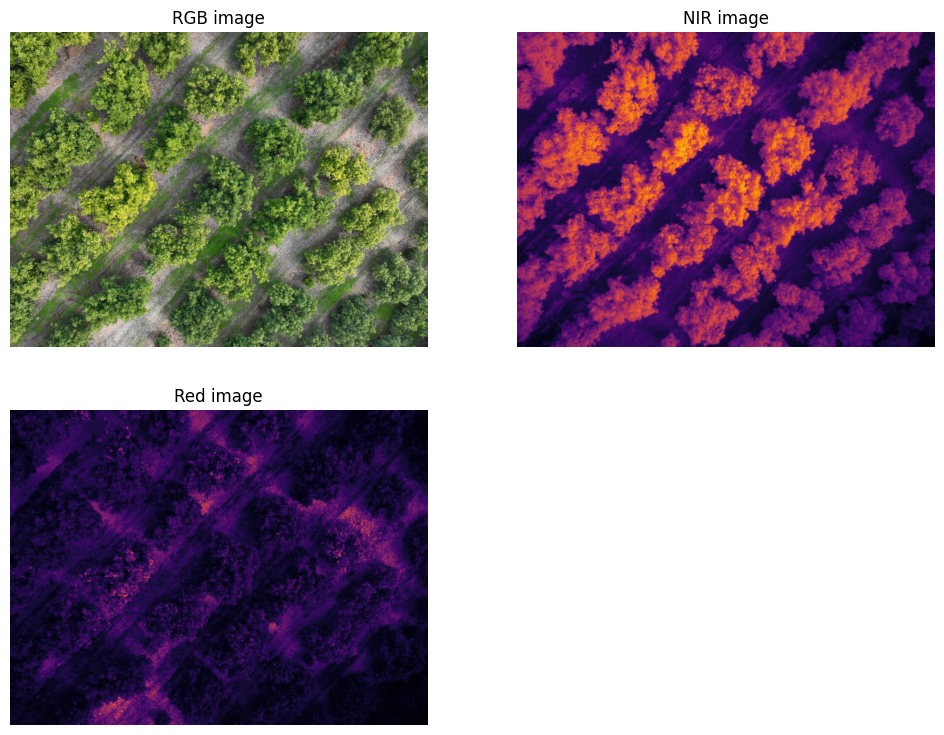

In [3]:
image_RGB = cv2.imread(images_path + '1_RGB.JPG', cv2.IMREAD_COLOR)
image_NIR = cv2.imread(images_path + '1_NIR.TIF', cv2.IMREAD_GRAYSCALE)
image_R = cv2.imread(images_path + '1_R.TIF', cv2.IMREAD_GRAYSCALE)

print('[Image info]')

print('RGB_Data size:', image_RGB.shape)
print('NIR_Data size:', image_NIR.shape)
print('Red_Data size:', image_R.shape)

# Resize RGB image to share dimensions with NIR and Red images
nir_height, nir_width = image_NIR.shape[:2]
image_RGB = cv2.resize(image_RGB, (nir_width, nir_height))
print('RGB_Data resized size:', image_RGB.shape)

image_RGB = cv2.cvtColor(image_RGB, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 9))

plt.subplot(2,2,1), plt.axis('off')
plt.title('RGB image')
plt.imshow(image_RGB)

plt.subplot(2,2,2), plt.axis('off')
plt.title('NIR image')
plt.imshow(image_NIR, cmap='inferno') # 'inferno' is good for high contrast in intensity

plt.subplot(2,2,3), plt.axis('off')
plt.title('Red image')
plt.imshow(image_R, cmap='inferno');

<font color='blue'>**Expected output:**  </font>

```
[Image info]
RGB_Data size: (3856, 5112, 3)
NIR_Data size: (1928, 2556)
Red_Data size: (1928, 2556)
RGB_Data resized size: (1928, 2556, 3)
```

<img src="https://raw.githubusercontent.com/jotaraul/cv_hub/refs/heads/main/segmentation/images_crops/expected_input_images.PNG" width="600">

## Segment Anything Model (SAM)

SAM is a **vision foundation model for segmentation** developed by **Meta AI** (formerly Facebook AI Research). It was trained on the extensive SA-1B dataset, which contains 1.1 billion segmentation masks, enabling the model to generalize effectively to new, unseen data due to its exposure to a highly diverse dataset.

> 🔍 <font color="#0072B2"><b>AI Exploration:</b> Foundation models</font>  
> **Suggested prompt**  
> *In the context of artificial intelligence, what is a foundation model? Taking the Segment Anything Model (SAM) as an example, explain what vision foundation models and large language models (LLMs) have in common and how they differ (input data, training, output and typical uses).*

SAM can generate masks for unfamiliar objects without task-specific retraining (**zero-shot**) and without assigning them a semantic class (**class-agnostic**). This marks a major breakthrough: before SAM, segmenting any object in any image without retraining wasn't possible.

What sets SAM apart is its role as the first **promptable segmentation** model. Users can guide the model's output using various prompts: points, boxes or masks (see Fig. 2). Note that SAM is not a semantic segmentation model, since it does not categorize pixels into predefined classes.

<center>
    <img src="https://raw.githubusercontent.com/jotaraul/cv_hub/refs/heads/main/image_segmentation/images/sam_promptable_segmentation.png" width="800"/>
    <figcaption>Fig. 2. Masks returned by SAM (in blue) for different prompts on the crop field image: (a) a foreground point (star), (b) a box, (c) a foreground point and a background point (cross), and (d-f) the three candidate masks returned for a single ambiguous point.</figcaption>
</center>$\\[5pt]$

> 🔍 <font color="#0072B2"><b>AI Exploration:</b> Promptable segmentation</font>  
> **Suggested prompt**  
> *In the context of image segmentation, what exactly is promptable segmentation? Taking the Segment Anything Model (SAM) as an example, explain which types of prompts it accepts (points, boxes, masks), what it returns for each one, how it handles ambiguous prompts (e.g. a single point on a shirt) and how it differs from semantic and instance segmentation.*

## Choose a SAM model to work with

You can choose from three options of checkpoint weights: ViT-B (91M), ViT-L (308M), and ViT-H (636M parameters). How do you choose the right one? The larger the number of parameters, the more accurate the masks usually are, but also the longer the time needed for inference (that is, mask generation) and the more GPU memory required. If you have limited GPU resources or need fast inference, go for ViT-B. Otherwise, choose ViT-H.

In this notebook we previously downloaded the ViT-H checkpoint weights, but you can try the other ones.


In [4]:
model_type = "vit_h"

sam = sam_model_registry[model_type](checkpoint=sam_checkpoint)

## Segmenting every region in an image

Since SAM can efficiently process **prompts**, masks for the entire image can be generated by sampling a large number of prompts over an image. This method was used to generate the dataset SA-1B.

The class `SamAutomaticMaskGenerator` implements this capability. It works by sampling single-point input prompts in a grid over the image, from each of which SAM can predict multiple masks. Then, masks are filtered for quality and deduplicated using non-maximum suppression. Additional options allow for further improvement of mask quality and quantity, such as running prediction on multiple crops of the image or postprocessing masks to remove small disconnected regions and holes.

There are several tunable parameters in automatic mask generation that control how densely points are sampled and what the thresholds are for removing low quality or duplicate masks. Additionally, generation can be automatically run on crops of the image to get improved performance on smaller objects, and post-processing can remove stray pixels and holes. Here is an example configuration that returns more masks than the default one, since it lowers the quality thresholds and also runs the prediction on image crops:

```
mask_generator_2 = SamAutomaticMaskGenerator(
    model=sam,
    points_per_side=32,
    pred_iou_thresh=0.86,
    stability_score_thresh=0.92,
    crop_n_layers=1,
    crop_n_points_downscale_factor=2,
    min_mask_region_area=100,  # Requires open-cv to run post-processing
)
```



For completeness, this is the full list of parameters, but you wouldn't need to modify most of them.

- `model` (Sam, default SAM): The SAM model to use for mask prediction.

- `points_per_side` (int or None, default 32): The number of points to be sampled along one side of the image. The total number of points is
`points_per_side**2`. If None, 'point_grids' must provide explicit point sampling.

- `points_per_batch` (int, default 64): Sets the number of points run simultaneously by the model. Higher numbers may be faster but use more GPU memory.

- `pred_iou_thresh` (float, default 0.88): A filtering threshold in [0,1], using the model's predicted mask quality.

- `stability_score_thresh` (float, default 0.95): A filtering threshold in [0,1], using the stability of the mask under changes to the cutoff used to binarize the model's mask predictions.

- `stability_score_offset` (float, default 1.0): The amount to shift the cutoff when calculating the stability score.
          
- `box_nms_thresh` (float, default 0.7): The box IoU cutoff used by non-maximum suppression to filter duplicate masks.

- `crop_n_layers` (int, default 0): If >0, mask prediction will be run again on crops of the image. Sets the number of layers to run, where each layer has 2**i_layer number of image crops.

- `crop_nms_thresh` (float, default 0.7): The box IoU cutoff used by non-maximum suppression to filter duplicate masks between different crops.
          
- `crop_overlap_ratio` (float, default 512/1500): Sets the degree to which crops overlap. In the first crop layer, crops will overlap by this fraction of the image length. Later layers with more crops scale down this overlap.

- `crop_n_points_downscale_factor` (int, default 1): The number of points-per-side sampled in layer n is scaled down by crop_n_points_downscale_factor**n.

- `point_grids` (list(np.ndarray) or None, default None): A list over explicit grids of points used for sampling, normalized to [0,1]. The nth grid in the list is used in the nth crop layer. Exclusive with points_per_side.

- `min_mask_region_area` (int, default 0): If >0, postprocessing will be applied to remove disconnected regions and holes in masks with area smaller than min_mask_region_area. Requires opencv.

- `output_mode` (str, default "binary_mask"): The form masks are returned in. Can be 'binary_mask', 'uncompressed_rle', or 'coco_rle'. 'coco_rle' requires pycocotools. For large resolutions, 'binary_mask' may consume large amounts of memory.

Cool! Let's create the automatic mask generator object:

In [5]:
sam.cuda()
mask_generator = SamAutomaticMaskGenerator(sam,
                                           stability_score_thresh=0.96,
                                           min_mask_region_area=100)

`SamAutomaticMaskGenerator` returns a list of masks, where each mask is a dict containing various information about the mask:

- `segmentation` - [np.ndarray] - the mask with (H, W) shape, and bool type.
- `area` - [int] - the area of the mask in pixels
- `bbox` - [List[int]] - the bounding box of the mask in xywh format
- `predicted_iou` - [float] - the model's own prediction for the quality of the mask
- `point_coords` - [List[List[float]]] - the sampled input point that generated this mask
- `stability_score` - [float] - an additional measure of mask quality
- `crop_box` - List[int] - the crop of the image used to generate this mask in xywh format.

### **<span style="color:green"><b><i>ASSIGNMENT 1: Region segmentation with SAM, what does the output look like?</i></b></span>**

Our first task is to run our `mask_generator` to retrieve the masks that SAM segments in the RGB image.

> 🛠️ <font color="#0B6B3A"><b>AI Coding Support:</b> Automatic mask generation with SAM</font>  
> **Suggested prompt**  
> *I need to use the `SamAutomaticMaskGenerator` class of the `segment_anything` library in Python to segment an image. Do not write the full solution. Explain what its `generate()` method expects as input (image type and channel order) and what it returns.*

In [6]:
# Measure the time taken for mask generation
start_time = time.time()  # Start timing

# Generate masks
# generate() espera la imagen en RGB y uint8 (H, W, 3), por eso usamos image_RGB ya convertida
masks = mask_generator.generate(image_RGB)

end_time = time.time()  # End timing
time_taken = end_time - start_time

print('[Results info]')

print(f"Time taken to generate masks: {time_taken:.2f} seconds")

[Results info]
Time taken to generate masks: 21.15 seconds


Now, in the next code cell, implement the needed code to print the total number of masks detected by SAM, and the content of the first mask (segmentation, area, etc.).

In [7]:
print('[Results info]')

print('Number of masks:', len(masks))

print('Mask[0] data:')
for key,value in masks[0].items():
  print (key,value)

[Results info]
Number of masks: 93
Mask[0] data:
segmentation [[False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]
 ...
 [False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]]
area 95969
bbox [1062, 193, 408, 343]
predicted_iou 1.0084173679351807
point_coords [[1078.3125, 331.375]]
stability_score 0.9778954982757568
crop_box [0, 0, 2556, 1928]


<font color='blue'>**Expected output (similar to):**  </font>

```
[Results info]
Number of masks: 93
Mask[0] data:
segmentation [[False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]
 ...
 [False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]]
area 95969
bbox [1062, 193, 408, 343]
predicted_iou 1.0084174871444702
point_coords [[1078.3125, 331.375]]
stability_score 0.9778954982757568
crop_box [0, 0, 2556, 1928]
```

### **<span style="color:green"><b><i>ASSIGNMENT 2: Computing NDVI values of vegetation</i></b></span>**

The **[Normalized Difference Vegetation Index (NDVI)](https://en.wikipedia.org/wiki/Normalized_difference_vegetation_index)** is a popular index used in remote sensing to assess vegetation health and density. It measures the difference between the Near-Infrared (NIR) and Red (R) spectral bands, which are sensitive to vegetation:

- NIR: Healthy vegetation reflects strongly in the Near-Infrared band.
- Red: Vegetation absorbs light in the Red band for photosynthesis, leading to low reflection.

> 🔍 <font color="#0072B2"><b>AI Exploration:</b> Vegetation indices beyond NDVI</font>  
> **Suggested prompt**  
> *In the context of precision agriculture, which vegetation indices besides NDVI are computed from multispectral images taken by drones, and what does each one measure?*

The NDVI is calculated using the formula:

$$
\text{NDVI} = \frac{\text{NIR} - \text{Red}}{\text{NIR} + \text{Red}}
$$

Values range from -1 to 1:
- Close to 1: Healthy, dense vegetation.
- Close to 0: Bare soil or sparse vegetation.
- Negative values: Water, clouds, or non-vegetative features.

Using the multispectral images provided (NIR and Red), your task is to compute the NDVI values of the entire image and show them.

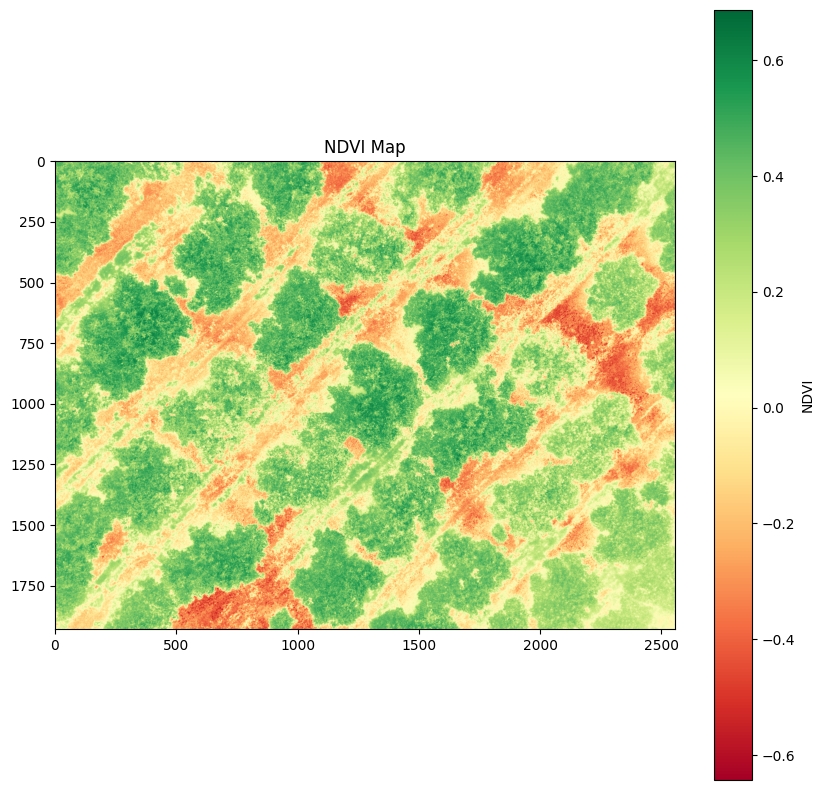

In [8]:
# Convert the bands to float for NDVI calculation
nir_band = image_NIR.astype(float)
red_band = image_R.astype(float)

# Compute NDVI: (NIR - Red) / (NIR + Red)
# sumo un valor muy pequeño abajo para que no haya division entre 0 en los pixeles donde NIR y Red son 0
ndvi = (nir_band - red_band) / (nir_band + red_band + 1e-10)

# Display the NDVI image using a color map
plt.figure(figsize=(10, 10))
plt.imshow(ndvi, cmap="RdYlGn")  # RdYlGn for a green-to-red color map (green = healthy vegetation)
plt.colorbar(label='NDVI')
plt.title("NDVI Map")
plt.show();

<font color='blue'>**Expected output:**  </font>

<img src="https://raw.githubusercontent.com/jotaraul/cv_hub/refs/heads/main/segmentation/images_crops/expected_ndvi_computation_result_1.PNG" width="400">

Our goal now will be to compute the mean and standard deviation of the NDVI values of the segmented regions. But first, let's start just by using the `np.ma.masked_where()` function along with the segmentation mask of the first detected one (`masks[0]`) and the computed NDVI values to produce a `masked_image` where just `True` values in the segmentation mask take their NDVI values.

> 🛠️ <font color="#0B6B3A"><b>AI Coding Support:</b> Masked arrays in NumPy</font>  
> **Suggested prompt**  
> *I am working in Python with images as NumPy arrays. Explain with a short example how `np.ma.masked_where()` works, how to keep only the pixels of a boolean mask, and how `mean()` and `std()` behave on a masked array. Do not write the full solution.*

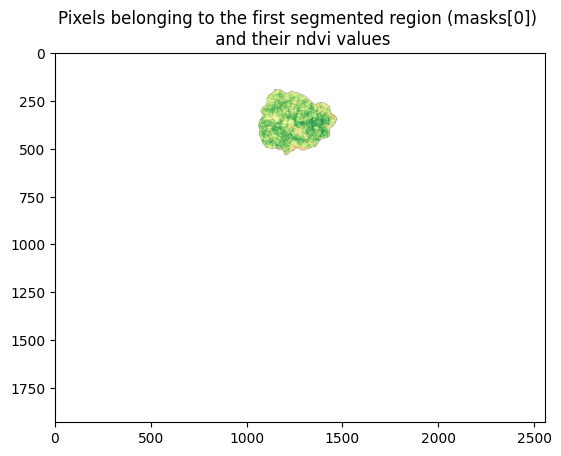

In [9]:
# Get the masked image
# masked_where oculta los valores donde la condicion es True, asi que hay que negar la mascara
masked_image = np.ma.masked_where(~masks[0]['segmentation'], ndvi)

# Show it!
plt.imshow(masked_image, cmap="RdYlGn")
plt.title('Pixels belonging to the first segmented region (masks[0]) \n and their ndvi values');

<font color='blue'>**Expected output:**  </font>

<img src="https://raw.githubusercontent.com/jotaraul/cv_hub/refs/heads/main/segmentation/images_crops/expected_masked_image_result_1.PNG" width="400">

Now that you know how to generate an image with just the NDVI values of a segmented region, let's compute the mean and standard deviation of those values per region. Then, they are included in the dictionary of each mask.

In [10]:
# Iterate over the masks
for mask in masks:
  # Get the masked image
  masked_image = np.ma.masked_where(~mask['segmentation'], ndvi)
  # Compute and store the mean
  mask['ndvi_mean'] = masked_image.mean()
  # Compute and store the standard deviation
  mask['ndvi_stdv'] = masked_image.std()

### **<span style="color:green"><b><i>ASSIGNMENT 3: Visualizing the results</i></b></span>**

Wow! We did a great job segmenting the regions appearing in the RGB image, computing the NDVI values using the NIR and Red ones, and retrieving their mean and standard deviation values of each mask. But something is missing... it would be cool to visualize the result of all this effort, wouldn't it?

Your task is to complete the following function that, over the initial RGB image, shows the $n$ biggest masks, and uses their mean NDVI value to draw in the middle of their bounding boxes a circle whose color means:

- Green: healthy vegetation (mean NDVI > 0.3).
- Orange: bare soil or sparse vegetation (0 < mean NDVI ≤ 0.3).
- Red: water, clouds or non-vegetative features (mean NDVI ≤ 0).

In [11]:
def show_segmented_regions(image, masks, show_n_biggest=0):

    if len(masks) == 0:
        return

    plt.figure(figsize=(12, 9))

    sorted_masks = sorted(masks, key=(lambda x: x['area']), reverse=True)

    if show_n_biggest:
      sorted_masks = sorted_masks[:show_n_biggest]

    # Let's create an image with transparency, being the fourth channel said
    # transparency
    image_masks = np.ones((sorted_masks[0]['segmentation'].shape[0],
                          sorted_masks[0]['segmentation'].shape[1],
                          4))
    image_masks[:,:,3] = 0

    # Only show ndvi_means if they have been computed
    if 'ndvi_mean' in sorted_masks[0]:
      image_circles = np.ones_like(image_masks, dtype=float)
      image_circles[:,:,3] = 0

    for mask in sorted_masks:

        m = mask['segmentation']
        color_mask = np.concatenate([np.random.random(3), [0.5]])
        image_masks[m] = color_mask

        if 'ndvi_mean' in mask:

          bbox = mask['bbox']

          if mask['ndvi_mean'] > 0.3:
            cv2.circle(image_circles,(int(bbox[0]+bbox[2]*0.5),int(bbox[1]+bbox[3]*0.5)), 25, (0,1,0,0.9), -1)

          elif mask['ndvi_mean'] >0:
            cv2.circle(image_circles,(int(bbox[0]+bbox[2]*0.5),int(bbox[1]+bbox[3]*0.5)), 25, (1,0.5,0,0.9), -1)

          else:
            cv2.circle(image_circles,(int(bbox[0]+bbox[2]*0.5),int(bbox[1]+bbox[3]*0.5)), 25, (1,0,0,0.9), -1)

    plt.imshow(image)
    ax = plt.gca()
    ax.set_autoscale_on(False)
    ax.imshow(image_masks)

    if 'ndvi_mean' in sorted_masks[0]:
      ax.imshow(image_circles)

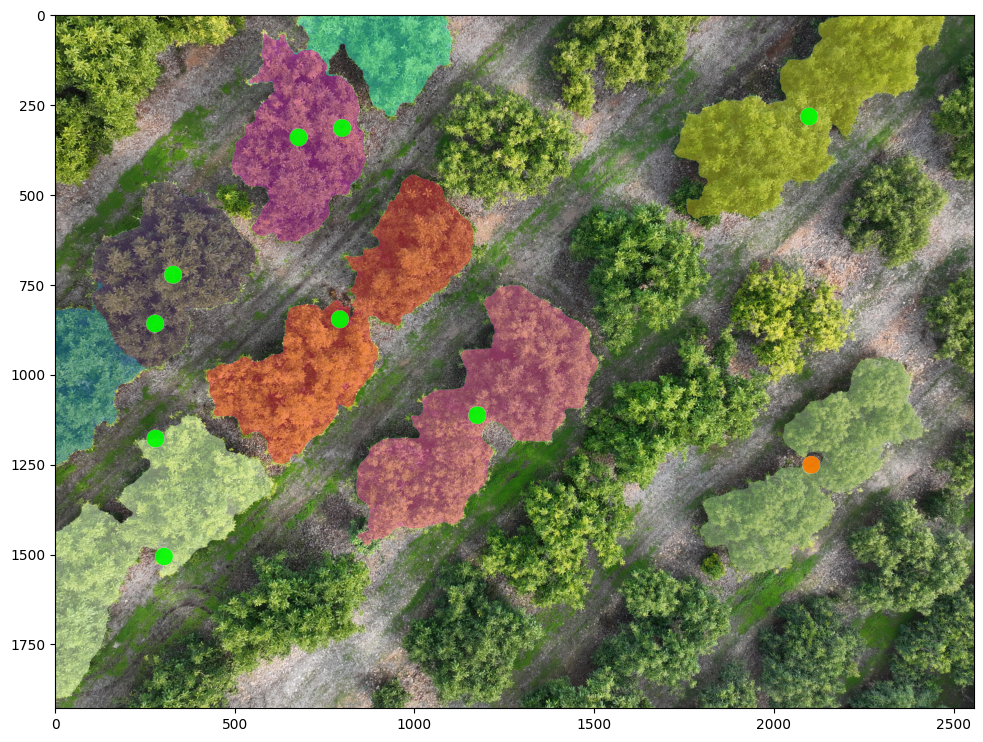

In [12]:
show_n_biggest = 10
show_segmented_regions(image_RGB, masks, show_n_biggest)

<font color='blue'>**Expected output (showing the 10 biggest masks):**  </font>

<img src="https://raw.githubusercontent.com/jotaraul/cv_hub/refs/heads/main/segmentation/images_crops/expected_segmentation_and_ndvi_result_1.PNG" width="400">

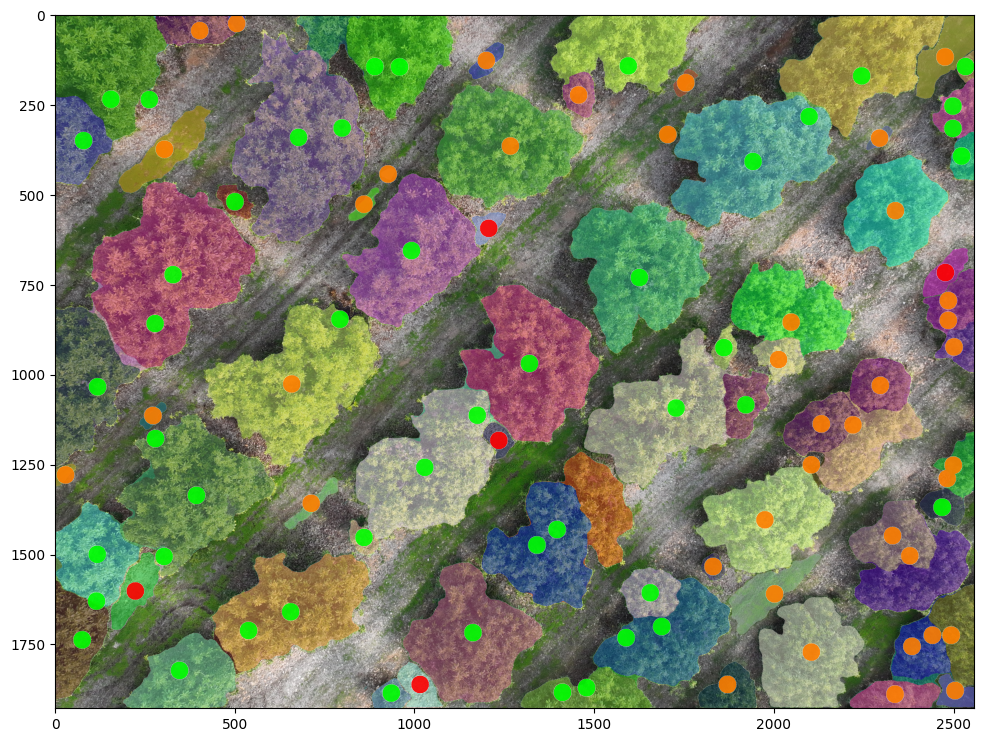

In [13]:
# Show all the masks
show_segmented_regions(image_RGB, masks)

<font color='blue'>**Expected output (showing all the masks):**  </font>

<img src="https://raw.githubusercontent.com/jotaraul/cv_hub/refs/heads/main/segmentation/images_crops/expected_segmentation_and_ndvi_result_2.PNG" width="400">

> 🧭 <font color="#B8860B"><b>AI Reflection:</b> Reading the NDVI of each tree</font>  
> **Suggested prompt**  
> *I have segmented trees with SAM and colored each one by its mean NDVI (green > 0.3, orange between 0 and 0.3, red ≤ 0). Guide me, without giving me the answer, to reason whether the mean NDVI of a mask is a reliable indicator of the health of a tree, and what could make it fail.*

✍️ **Your notes / key takeaways:**

<p style="margin: 4px 0px 6px 5px; color:blue"><i>La media del NDVI da una idea general, pero no es del todo fiable. La máscara de SAM puede incluir suelo o sombra entre las ramas, sobre todo en los bordes, y eso baja la media aunque el árbol esté sano. También influye la iluminación (las zonas en sombra reflejan menos) y que las imágenes RGB y NIR/Red vienen de sensores distintos: aunque redimensionamos la RGB, puede que no estén perfectamente alineadas. Además SAM segmenta cosas que no son árboles (caminos, trozos de suelo), y esas también reciben un círculo. Por eso conviene mirar también la desviación típica: si es alta, la región es muy heterogénea, por ejemplo un árbol con una parte seca, y la media sola lo esconde. Los umbrales 0 y 0.3 también son bastante generales y dependen del cultivo.</i></p>

## Conclusion

Congratulations on completing this notebook! 🎉

In this notebook, we explored the power of **learning-based segmentation** techniques using the cutting-edge **Segment Anything Model (SAM)**. We went through the process of:

1. **Loading and Visualizing Multispectral Data**: We worked with **RGB**, **Near-Infrared (NIR)**, and **Red** images captured by a multispectral camera mounted on a drone, which provided us with the necessary data to monitor vegetation.
   
2. **Segmenting Regions with SAM**: You successfully used the **Segment Anything Model (SAM)** to segment individual trees from the RGB image, demonstrating SAM's ability to generalize to new images without task-specific retraining (zero-shot).

3. **Computing NDVI (Normalized Difference Vegetation Index)**: Using the NIR and Red bands, you computed the **NDVI**, a crucial index in precision agriculture that helps monitor the health and vigor of vegetation. We applied NDVI on the segmented trees, which allowed for personalized monitoring of each tree's health based on its spectral properties.

4. **Visualizing Results**: The final visualization included not only the segmented regions but also overlaid **NDVI values** represented by color-coded circles, allowing for an easy assessment of vegetation health across the entire image.

Through this notebook, you've gained hands-on experience with **multispectral image analysis**, **region segmentation using SAM**, and the **computation and interpretation of NDVI**, which are relevant tools in the fields of **remote sensing** and **precision agriculture**.

Well done! You've taken important steps toward understanding how computer vision can be applied to solve real-world problems in environmental monitoring and sustainability. 🌱


## <font color="orange"><b><i>AI Appendix</i></b></font>

- **Model/tool used:**
  <p style="margin: 4px 0px 6px 5px; color:blue"><i>Gemini</i></p>

- **What I used AI for:**
  <p style="margin: 4px 0px 6px 5px; color:blue"><i>Pillarle el truco a np.ma.masked_where y explicar por qué la media del NDVI puede engañar.</i></p>

- **Most and least useful proposed AI interactions:**
  <p style="margin: 4px 0px 6px 5px; color:blue"><i>Útil ver cuándo falla el NDVI; la parte teórica de foundation models no me aportó nada.</i></p>

- **Most useful personal AI interaction:**
  <p style="margin: 4px 0px 6px 5px; color:blue"><i>Ver cómo pintar los círculos transparentes encima sin cargarme la foto de fondo.</i></p>

- **What I verified, adapted or decided myself:**
  <p style="margin: 4px 0px 6px 5px; color:blue"><i>Le sumé 1e-10 al NDVI para no dividir por 0 y comprobé que la máscara fuera negada (~).</i></p>

## This notebook was designed using the following sources of information:
- SAM paper: https://arxiv.org/abs/2304.02643
- https://github.com/facebookresearch/segment-anything/blob/main/notebooks/automatic_mask_generator_example.ipynb
- https://github.com/facebookresearch/segment-anything/blob/main/segment_anything/automatic_mask_generator.py